# E-commerce Customer Analytics: Sales Trends, Cohort Retention & RFM Segmentation

**Dataset:** [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail): 541,909 transactions from a UK-based online gift retailer (Dec 2010 to Dec 2011), mostly sold to wholesalers.

**Business questions**
1. How are revenue and customer activity trending month to month?
2. Which products and markets drive the business?
3. When do customers place orders?
4. How well does the business retain newly acquired customers?
5. Who are the most valuable customers, and which customers are at risk of churning?
6. Which products are frequently bought together?

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from retail_analysis import basket, cohort, data, metrics, rfm

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_colwidth", 45)

## 1. Load and inspect the raw data
The dataset is downloaded from UCI automatically on first run and cached in `data/`.

In [2]:
raw = data.load_raw()
print(raw.shape)
raw.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [3]:
raw.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"541,909.00",NaN,NaN,NaN,9.55,"-80,995.00",1.00,3.00,10.00,"80,995.00",218.08
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,"541,909.00",NaN,NaN,NaN,4.61,"-11,062.06",1.25,2.08,4.13,"38,970.00",96.76
CustomerID,"406,829.00",<NA>,<NA>,<NA>,"15,287.69","12,346.00","13,953.00","15,152.00","16,791.00","18,287.00","1,713.60"
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
raw.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

**Data quality issues found:**
- ~25% of rows have no `CustomerID` (guest checkouts): kept for sales metrics, excluded from customer-level analysis.
- Cancelled invoices (prefixed with `C`) have negative quantities.
- Some rows have zero/negative prices or are non-product lines (postage, bank charges, manual adjustments).
- Exact duplicate rows.
- A few huge orders were immediately cancelled (e.g. 80,995 × *Paper Craft, Little Birdie*). Those would distort product rankings.

## 2. Clean the data

In [5]:
df = data.clean(raw)
data.cleaning_report(raw, df)

raw_rows              541,909.00
duplicate_rows          5,268.00
cancelled_rows          9,288.00
missing_customer_id   135,080.00
clean_rows            519,488.00
rows_removed_pct            4.14
dtype: float64

In [6]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,InvoiceMonth,Weekday,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8


## 3. Headline KPIs

In [7]:
kpis = metrics.kpis(df)
kpis

total_revenue              9,817,322.04
orders                        19,612.00
customers                      4,322.00
products                       3,798.00
countries                         38.00
avg_order_value                  500.58
repeat_customer_rate_pct          65.25
dtype: float64

In [8]:
print(f"Top 20% of customers generate {metrics.pareto_share(df):.1f}% of revenue")

Top 20% of customers generate 73.7% of revenue


## 4. Monthly sales trend

In [9]:
monthly = metrics.monthly_revenue(df)
monthly

,revenue,orders,customers,avg_order_value,revenue_mom_pct
InvoiceMonth,,,,,
2010-12,"766,651.64",1539,883,498.15,NaN
2011-01,"587,062.70",1068,735,549.68,-23.43
2011-02,"505,292.29",1088,755,464.42,-13.93
2011-03,"680,301.35",1431,971,475.40,34.64
2011-04,"490,262.89",1222,847,401.20,-27.93
2011-05,"733,576.71",1652,1052,444.05,49.63
2011-06,"689,407.26",1509,985,456.86,-6.02
2011-07,"681,329.17",1442,942,472.49,-1.17
2011-08,"717,092.60",1333,930,537.95,5.25


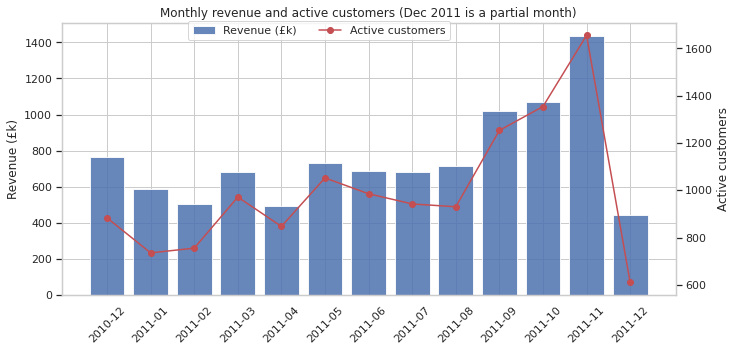

In [10]:
fig, ax1 = plt.subplots(figsize=(11, 5))
x = monthly.index.astype(str)
ax1.bar(x, monthly["revenue"] / 1e3, alpha=0.85, label="Revenue (£k)")
ax1.set_ylabel("Revenue (£k)")
ax1.tick_params(axis="x", rotation=45)
ax2 = ax1.twinx()
ax2.plot(x, monthly["customers"], color="C3", marker="o", label="Active customers")
ax2.set_ylabel("Active customers")
ax2.grid(False)
ax1.set_title("Monthly revenue and active customers (Dec 2011 is a partial month)")
fig.legend(loc="upper center", bbox_to_anchor=(0.45, 0.9), ncol=2)
plt.show()

**Insight:** Revenue is flat at roughly £500k to £730k/month through the first half of 2011, then climbs sharply from September. November 2011 is the peak month at £1.44M, **2.8× February**. September through November alone bring in **~36% of annual revenue**. Growth comes from more active customers, not from larger orders, which suggests wholesalers stocking up for Christmas.

## 5. Products and markets

In [11]:
top = metrics.top_products(df)
top

,StockCode,Description,Revenue,Quantity,Orders
0,22423,REGENCY CAKESTAND 3 TIER,"169,505.64",13445,1937
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"100,052.42",35348,2244
2,47566,PARTY BUNTING,"98,610.18",18090,1674
3,85099B,JUMBO BAG RED RETROSPOT,"92,595.77",47488,2076
4,23084,RABBIT NIGHT LIGHT,"66,807.63",30709,991
5,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"63,834.94",18922,1152
6,84879,ASSORTED COLOUR BIRD ORNAMENT,"58,878.61",36333,1452
7,79321,CHILLI LIGHTS,"53,761.61",10225,658
8,23298,SPOTTY BUNTING,"42,493.68",8316,1138
9,22386,JUMBO BAG PINK POLKADOT,"41,607.39",21004,1209


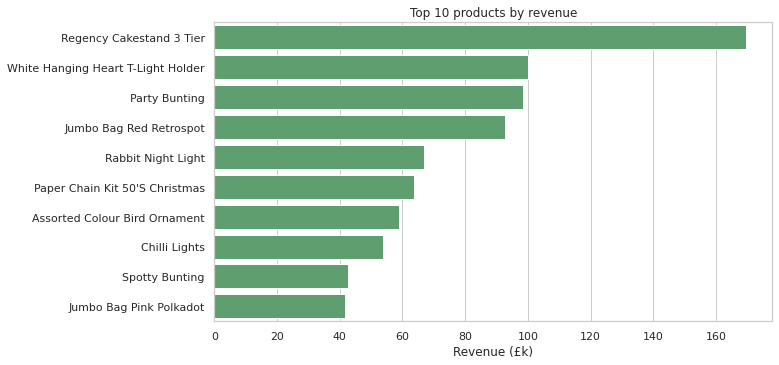

In [12]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(x=top["Revenue"] / 1e3, y=top["Description"].str.title(), ax=ax, color="C2")
ax.set_xlabel("Revenue (£k)")
ax.set_ylabel("")
ax.set_title("Top 10 products by revenue")
plt.show()

In [13]:
countries = metrics.revenue_by_country(df)
countries

,Revenue,Customers,Orders,Share_pct
Country,,,,
United Kingdom,"8,317,156.61",3907,17763,84.72
Netherlands,"283,443.54",9,93,2.89
EIRE,"262,017.03",3,280,2.67
Germany,"203,594.58",94,441,2.07
France,"182,697.39",87,378,1.86
Australia,"137,062.85",9,53,1.40
Switzerland,"52,712.50",21,48,0.54
Spain,"52,029.97",29,87,0.53
Japan,"37,314.37",8,19,0.38


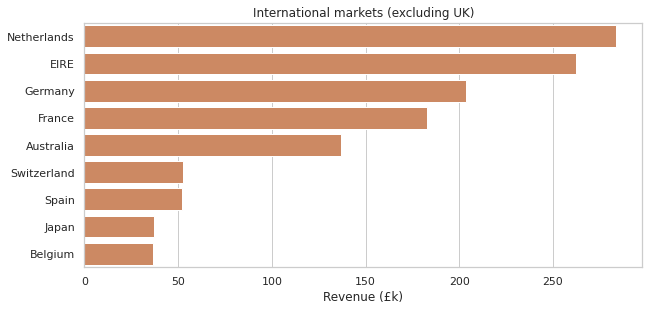

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.5))
non_uk = countries.drop(index="United Kingdom")
sns.barplot(x=non_uk["Revenue"] / 1e3, y=non_uk.index, ax=ax, color="C1")
ax.set_xlabel("Revenue (£k)")
ax.set_ylabel("")
ax.set_title("International markets (excluding UK)")
plt.show()

**Insight:** The UK accounts for **~85% of revenue**. The Netherlands and EIRE come next, each with a handful of very large wholesale accounts (9 and 3 customers). Germany and France have many more customers (~90 each) and look like the most scalable international markets.

## 6. When do customers order?

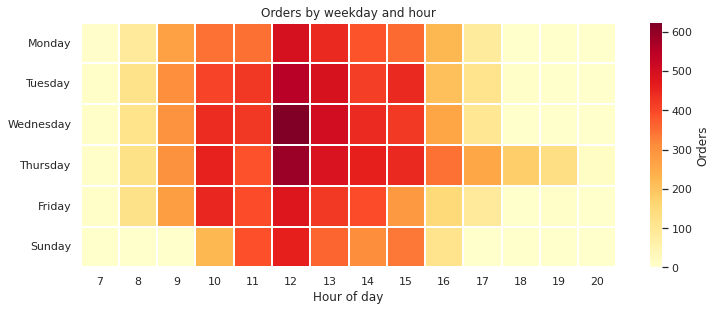

In [15]:
heat = metrics.weekday_hour_heatmap(df)
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(heat, cmap="YlOrRd", ax=ax, cbar_kws={"label": "Orders"}, linewidths=0.3)
ax.set_title("Orders by weekday and hour")
ax.set_xlabel("Hour of day")
ax.set_ylabel("")
plt.show()

**Insight:** Orders peak at **12:00 to 13:00 on Tuesday to Thursday**. There are no Saturday orders at all, and the store is quiet after 17:00, which fits a B2B customer base working office hours. Marketing emails and promotions should go out late morning on weekdays.

## 7. Cohort retention analysis

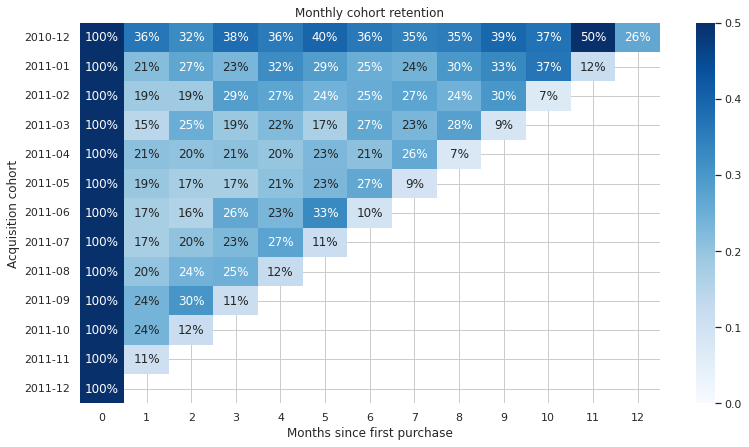

In [16]:
retention = cohort.retention_matrix(df)
fig, ax = plt.subplots(figsize=(13, 7))
r = retention.copy()
r.index = r.index.astype(str)
sns.heatmap(r, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=0.5, ax=ax)
ax.set_title("Monthly cohort retention")
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("Acquisition cohort")
plt.show()

In [17]:
print(f"Average month-1 retention: {retention[1].mean():.1%}")

Average month-1 retention: 20.4%


**Insight:** Only **~20% of new customers come back the following month**. The December 2010 cohort stands out, keeping 30% to 50% of its customers every month. It probably contains long-standing customers whose earlier purchases fall before the dataset starts. Later cohorts level off around 20% to 25%, so onboarding and second-purchase campaigns are the biggest retention lever. (The last column of each cohort covers December 2011, which is only a partial month.)

## 8. RFM segmentation

In [18]:
rfm_table = rfm.build_rfm(df)
rfm_table.describe()

,Recency,Frequency,Monetary
count,"4,322.00","4,322.00","4,322.00"
mean,92.47,4.22,"1,921.94"
std,100.35,7.58,"8,312.51"
min,0.00,1.00,2.90
25%,17.00,1.00,301.42
50%,50.00,2.00,656.43
75%,143.00,5.00,"1,613.90"
max,373.00,205.00,"278,742.02"


In [19]:
scored = rfm.score_rfm(rfm_table)
scored.head()

,Recency,Frequency,Monetary,R,F,M,RFM_Score,Segment
CustomerID,,,,,,,,
12347,2,7,"4,310.00",5,5,5,555,Champions
12348,75,4,"1,437.24",2,4,4,244,At Risk
12349,18,1,"1,457.55",4,1,4,414,New Customers
12350,310,1,294.40,1,1,2,112,Hibernating
12352,36,6,"1,265.41",3,5,4,354,Loyal Customers


In [20]:
segments = rfm.segment_summary(scored)
segments

,Customers,AvgRecency,AvgFrequency,AvgMonetary,TotalRevenue,CustomerShare_pct,RevenueShare_pct
Segment,,,,,,,
Champions,1111,12.49,9.96,"5,118.43","5,686,579.11",25.71,68.46
Loyal Customers,828,36.69,3.63,"1,388.29","1,149,507.09",19.16,13.84
At Risk,654,150.00,3.39,"1,125.71","736,211.43",15.13,8.86
Hibernating,1075,217.45,1.10,413.71,"444,736.90",24.87,5.35
Need Attention,346,52.20,1.14,456.07,"157,800.61",8.01,1.90
Potential Loyalists,171,17.77,1.43,522.70,"89,381.79",3.96,1.08
New Customers,137,17.70,1.00,309.69,"42,427.62",3.17,0.51


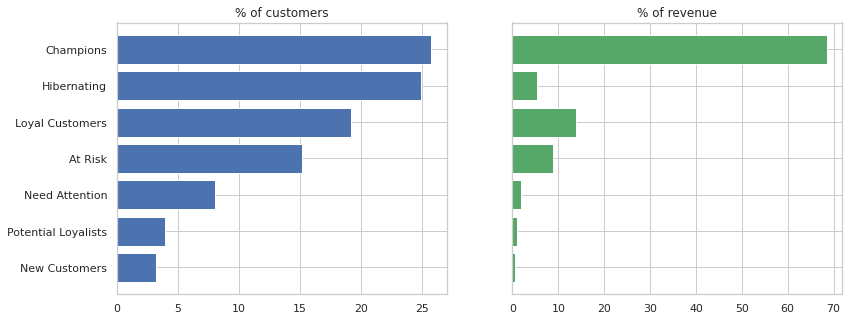

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
ordered = segments.sort_values("Customers")
axes[0].barh(ordered.index, ordered["CustomerShare_pct"], color="C0")
axes[0].set_title("% of customers")
axes[1].barh(ordered.index, ordered["RevenueShare_pct"], color="C2")
axes[1].set_title("% of revenue")
plt.show()

**Insight:** **Champions** are ~26% of customers but bring in **~68% of revenue**. **At Risk** customers (used to buy often, now inactive for ~150 days) are 15% of customers and ~9% of revenue, so a win-back campaign aimed at them has the best expected return.

## 9. K-Means clustering (unsupervised validation)
RFM features are log-transformed and standardised before clustering.

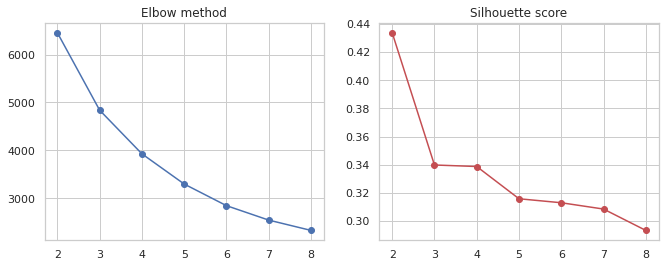

,inertia,silhouette
k,,
2,"6,456.80",0.43
3,"4,838.58",0.34
4,"3,927.01",0.34
5,"3,296.03",0.32
6,"2,844.20",0.31
7,"2,542.37",0.31
8,"2,327.07",0.29


In [22]:
k_scores = rfm.choose_k(rfm_table)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_scores.index, k_scores["inertia"], marker="o")
axes[0].set_title("Elbow method")
axes[1].plot(k_scores.index, k_scores["silhouette"], marker="o", color="C3")
axes[1].set_title("Silhouette score")
plt.show()
k_scores

k=2 has the highest silhouette score, but it only separates active from inactive customers. **k=4** sits near the elbow, keeps a good silhouette score, and produces segments the business can act on.

In [23]:
clustered = rfm.kmeans_clusters(rfm_table, k=4)
names = {0: "VIP", 1: "Loyal", 2: "Occasional", 3: "Lapsed"}
clustered["ClusterName"] = pd.Categorical(clustered["Cluster"].map(names), categories=names.values())
profile = clustered.groupby("ClusterName", observed=True).agg(
    Customers=("Recency", "size"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean"),
    TotalRevenue=("Monetary", "sum"),
)
profile["RevenueShare_pct"] = 100 * profile["TotalRevenue"] / profile["TotalRevenue"].sum()
profile

,Customers,AvgRecency,AvgFrequency,AvgMonetary,TotalRevenue,RevenueShare_pct
ClusterName,,,,,,
VIP,680,11.36,13.90,"7,848.74","5,337,143.68",64.25
Loyal,1187,69.31,4.09,"1,657.86","1,967,881.43",23.69
Occasional,813,16.79,2.18,552.04,"448,804.66",5.40
Lapsed,1642,180.27,1.31,336.67,"552,814.78",6.66


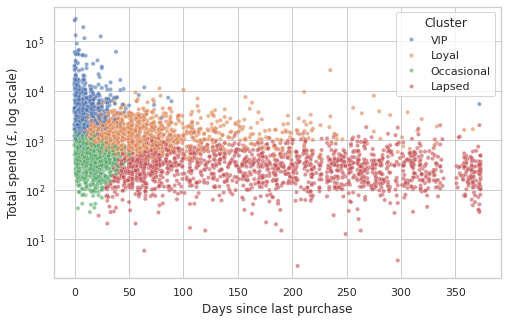

In [24]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=clustered, x="Recency", y="Monetary", hue="ClusterName", alpha=0.6, s=18, ax=ax)
ax.set_yscale("log")
ax.set_xlabel("Days since last purchase")
ax.set_ylabel("Total spend (£, log scale)")
ax.legend(title="Cluster")
plt.show()

**Insight:** The clusters line up with the rule-based RFM segments. The **VIP** cluster (~16% of customers, bought within the last ~11 days, ~14 orders on average) brings in **~64% of revenue**. The **Lapsed** cluster is the largest (38% of customers) but brings in under 7% of revenue.

## 10. Market basket analysis

In [25]:
pairs = basket.product_pairs(df)
pairs

,item_a,item_b,support,confidence_a_to_b,confidence_b_to_a,lift
0,JUMBO BAG PINK POLKADOT,JUMBO BAG RED RETROSPOT,0.04,0.68,0.39,6.38
1,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.04,0.75,0.72,14.01
2,JUMBO BAG RED RETROSPOT,JUMBO STORAGE BAG SUKI,0.04,0.35,0.61,5.75
3,JUMBO BAG RED RETROSPOT,JUMBO SHOPPER VINTAGE RED PAISLEY,0.03,0.33,0.58,5.46
4,LUNCH BAG BLACK SKULL.,LUNCH BAG RED RETROSPOT,0.03,0.50,0.41,6.34
5,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE RED,0.03,0.65,0.61,12.16
6,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.03,0.62,0.82,16.04
7,LUNCH BAG PINK POLKADOT,LUNCH BAG RED RETROSPOT,0.03,0.56,0.39,7.01
8,PINK REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.03,0.77,0.56,14.38
9,JUMBO BAG BAROQUE BLACK WHITE,JUMBO BAG RED RETROSPOT,0.03,0.62,0.28,5.90


**Insight:** Colour and pattern variants of the same product sell together: Regency teacups (lift ≈ 14 to 16), Jumbo bags, lunch bags, Bakelike alarm clocks. Bundles ("buy the set") and "frequently bought together" recommendations would work well here.

## 11. Recommendations

| # | Recommendation | Evidence |
|---|---|---|
| 1 | **Protect the Champions / VIPs** with account management, early access to seasonal ranges and volume discounts | ~26% of customers generate ~68% of revenue |
| 2 | **Run win-back campaigns for At-Risk customers** before they lapse | 654 customers, ~£736k historical revenue, ~150 days inactive |
| 3 | **Invest in second-purchase onboarding** for new customers | Only ~20% of a cohort returns in month 1 |
| 4 | **Plan inventory and marketing around the Sep to Nov peak** | ~36% of annual revenue in 3 months |
| 5 | **Bundle and cross-sell colour/pattern variants** | Product pairs with lift of 5 to 16 |
| 6 | **Schedule campaigns for weekday late mornings**, expand in Germany and France | Order peak Tue to Thu 12:00; largest non-UK customer bases |